In [17]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from src.pre_process_filter import build_table, FEATURE_NAMES

In [4]:
table = build_table("../data/hapt_raw/RawData")
print(table.shape)
print(table["activity"].value_counts())
table.head()

(5605, 26)
activity
standing        1979
sitting         1801
walking         1722
stand_to_sit      70
sit_to_stand      33
Name: count, dtype: int64


,user,activity,mean_acc_x,mean_acc_y,mean_acc_z,mean_gyro_x,mean_gyro_y,mean_gyro_z,std_acc_x,std_acc_y,...,min_acc_z,min_gyro_x,min_gyro_y,min_gyro_z,max_acc_x,max_acc_y,max_acc_z,max_gyro_x,max_gyro_y,max_gyro_z
0,1,standing,1.019365,-0.124227,0.099631,0.007699,-0.002806,0.002277,0.001589,0.003273,...,0.088818,-0.010597,-0.012082,-0.010370,1.022712,-0.116858,0.109164,0.042735,0.008227,0.014257
1,1,standing,1.019427,-0.123014,0.096925,0.014400,-0.004083,0.003807,0.001920,0.005011,...,0.079260,-0.023920,-0.025518,-0.010370,1.024654,-0.109612,0.104554,0.059664,0.004765,0.024099
2,1,standing,1.019900,-0.125065,0.092817,0.007815,-0.007051,0.005730,0.002883,0.006448,...,0.079260,-0.023920,-0.033425,-0.009635,1.027009,-0.109612,0.104554,0.059664,0.004352,0.029946
3,1,standing,1.020378,-0.130490,0.087506,-0.002972,-0.004509,0.003714,0.002558,0.004021,...,0.077296,-0.018743,-0.033425,-0.013885,1.027009,-0.117068,0.097712,0.024916,0.008460,0.029946
4,1,standing,1.020225,-0.130187,0.085049,0.001289,-0.000352,0.000610,0.001988,0.003886,...,0.074674,-0.016248,-0.021649,-0.015214,1.025283,-0.121788,0.093337,0.045118,0.015344,0.021881


In [5]:
table.to_csv("../data/hapt_filtered.csv", index=False)

In [9]:
TEST_USERS = [2, 4, 9, 10, 12, 13, 18, 20, 24]

train = table[table["user"].isin(TEST_USERS)]
test = table[table["user"].isin(TEST_USERS) == False]

X_train = train[FEATURE_NAMES]
y_train = train["activity"]
X_test = test[FEATURE_NAMES]
y_test = test["activity"]

print("Training windows:", len(train))
print("Test windows:", len(test))

Training windows: 1593
Test windows: 4012


In [15]:
results = {}

def runModel(model, name):
    predictions = model.predict(X_test)
    print(name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print(classification_report(y_test, predictions))
    results[name] = f1_score(y_test, predictions, average="macro")
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation=45)
    plt.title(name)
    plt.tight_layout()
    plt.show()

Baseline (24 features)
Accuracy: 0.9140079760717846
              precision    recall  f1-score   support

sit_to_stand       1.00      0.78      0.88        23
     sitting       0.84      0.94      0.89      1293
stand_to_sit       0.64      0.83      0.72        47
    standing       0.94      0.84      0.88      1423
     walking       0.99      0.99      0.99      1226

    accuracy                           0.91      4012
   macro avg       0.88      0.87      0.87      4012
weighted avg       0.92      0.91      0.91      4012



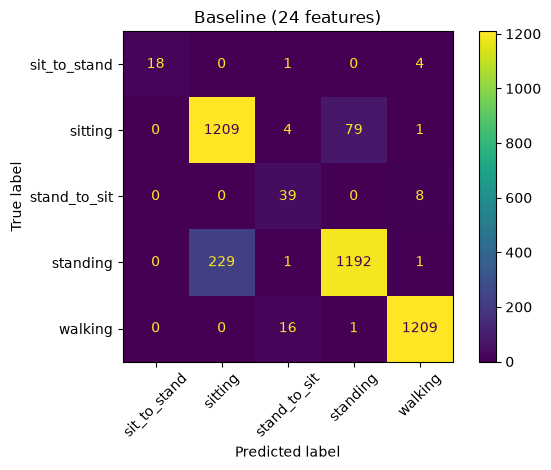

In [18]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
runModel(model, "Baseline (24 features)")

max_acc_x     0.090027
mean_acc_y    0.080294
min_acc_x     0.078135
std_acc_x     0.074526
std_acc_y     0.070572
max_acc_y     0.067910
min_acc_y     0.066138
std_acc_z     0.055616
std_gyro_x    0.054310
min_gyro_x    0.045221
dtype: float64


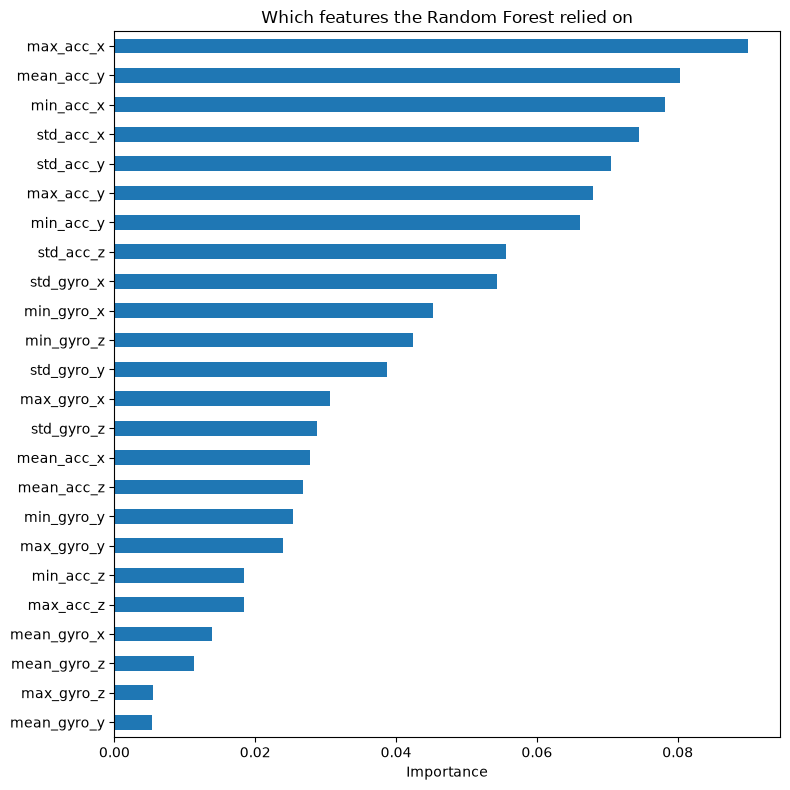

In [19]:
importance = pd.Series(model.feature_importances_, index=FEATURE_NAMES)
importance = importance.sort_values(ascending=False)
print(importance.head(10))

importance.plot.barh(figsize=(8, 8))
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Which features the Random Forest relied on")
plt.tight_layout()
plt.show()

Balanced class weights
Accuracy: 0.9152542372881356
              precision    recall  f1-score   support

sit_to_stand       1.00      0.83      0.90        23
     sitting       0.84      0.93      0.88      1293
stand_to_sit       0.83      0.81      0.82        47
    standing       0.94      0.83      0.88      1423
     walking       0.99      1.00      0.99      1226

    accuracy                           0.92      4012
   macro avg       0.92      0.88      0.90      4012
weighted avg       0.92      0.92      0.92      4012



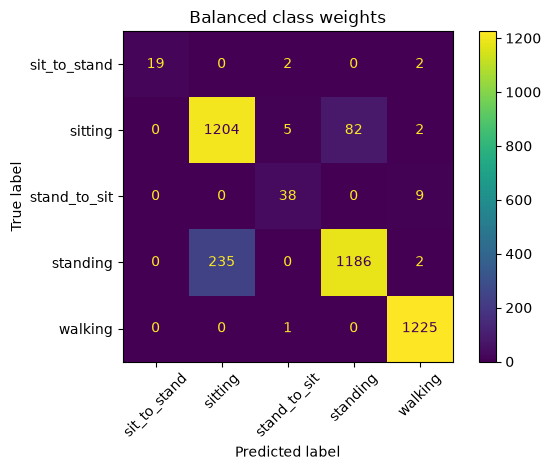

In [20]:
model_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
model_balanced.fit(X_train, y_train)
runModel(model_balanced, "Balanced class weights")